# Predicting Hourly Bike-Sharing Demand
**Team:** Donya Bagheri, Chia-Chi Chang, Siyi Li, Zhijing Wu

**Research question:** How well can time and weather predict hourly rental counts, and what can the results tell us about operational planning?

Capital Bikeshare, Washington, D.C., 2011–2012. Each row is one recorded hour; `cnt` counts rental events, not unique customers or required bicycles.

**Run in Colab:** Upload `hour.csv` to the Files panel, then run all cells from top to bottom. The saved outputs come from the original simplified notebook; this edition changes explanations and comments only. A fresh runtime requires running the earlier cells before the demo.

**Scope:** Historical-average baseline, Linear Regression, and Random Forest.

**Source:** Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

**Edition:** Concise English presentation and submission edition.


## 1. Load and check the data
Read the hourly CSV and check its size, missing cells, and duplicate rows. One row represents one recorded hour; `cnt` is the number of rental events.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("hour.csv")
print("Rows and columns:", df.shape)
print("Missing cells:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()


Rows and columns: (17379, 17)
Missing cells: 0
Duplicate rows: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Combine date and hour into a timestamp and sort chronologically. Check for missing whole hours separately from empty cells. An unrecorded hour is not necessarily an hour with zero rentals.


In [2]:
df["dteday"] = pd.to_datetime(df["dteday"])
df["timestamp"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
df = df.sort_values("timestamp").reset_index(drop=True)
all_hours = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h")
missing_hours = all_hours.difference(df["timestamp"])
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Duplicate hours:", df["timestamp"].duplicated().sum())
print("Unrecorded hours:", len(missing_hours))
print("casual + registered equals cnt:", (df["casual"] + df["registered"] == df["cnt"]).all())


Date range: 2011-01-01 00:00:00 to 2012-12-31 23:00:00
Duplicate hours: 0
Unrecorded hours: 165
casual + registered equals cnt: True


**Data checks:** 17,379 rows; no empty cells or duplicate hours; 165 unrecorded hours retained as gaps. Exclude `casual` and `registered`: their sum equals the target `cnt`, so including them would reveal the answer. Exclude the ID `instant`. Weather inputs remain in their original normalized units; temperature conversion descriptions differ between the source Readme and UCI page.


## 2. Explore demand patterns
Compare mean hourly rentals on working and non-working days. These descriptive charts use the full dataset to summarize observed patterns; they are not independent evidence of predictive performance.


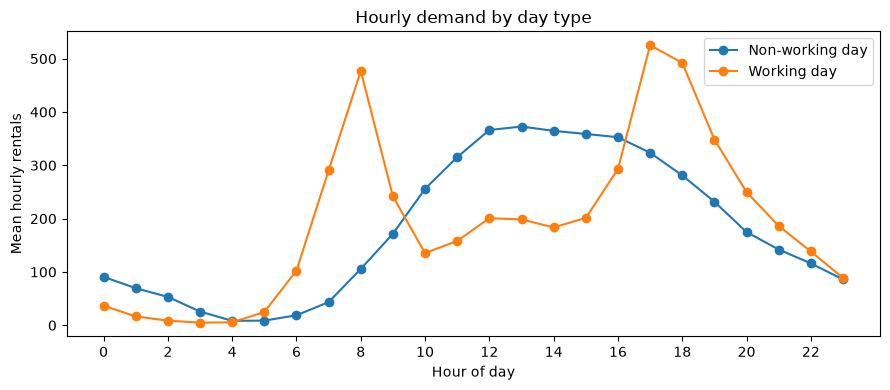

In [3]:
hourly = df.groupby(["hr", "workingday"])["cnt"].mean().unstack()
hourly.columns = ["Non-working day", "Working day"]
hourly.plot(figsize=(9, 4), marker="o")
plt.xlabel("Hour of day")
plt.ylabel("Mean hourly rentals")
plt.title("Hourly demand by day type")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


**Finding:** Working days show morning and evening commute peaks; non-working days show a broader midday/afternoon peak. Different day types need different hourly planning profiles.


Compare mean hourly demand by month, separately for 2011 and 2012. This avoids confusing monthly patterns with differences between years.


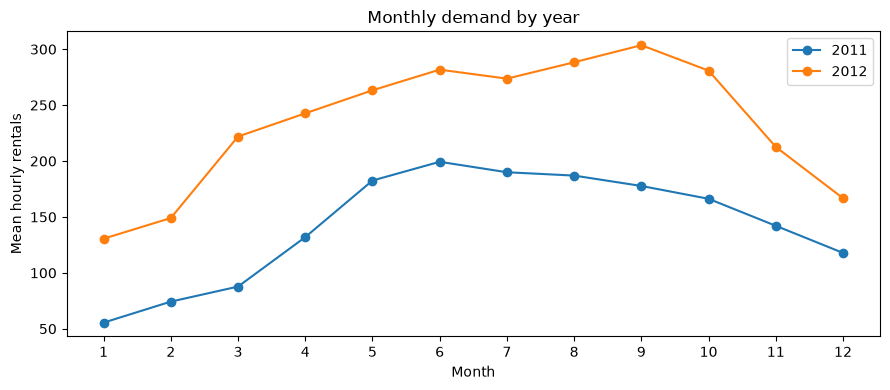

In [4]:
monthly = df.groupby(["mnth", "yr"])["cnt"].mean().unstack()
monthly.columns = ["2011", "2012"]
monthly.plot(figsize=(9, 4), marker="o")
plt.xlabel("Month")
plt.ylabel("Mean hourly rentals")
plt.title("Monthly demand by year")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


**Finding:** Demand varies by month and is generally higher in 2012. Two years of observations do not establish a lasting growth trend.


Summarize the number of observations and mean rentals for each weather category. Category 4 has only three observations, so its average is unstable.


            count   mean
weathersit              
1           11413  204.9
2            4544  175.2
3            1419  111.6
4               3   74.3


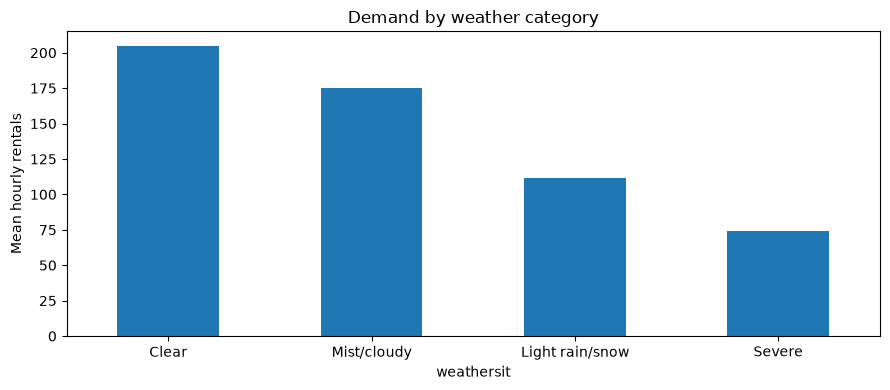

In [5]:
weather = df.groupby("weathersit")["cnt"].agg(["count", "mean"])
print(weather.round(1))
weather["mean"].plot.bar(figsize=(9, 4), rot=0)
plt.xticks(range(4), ["Clear", "Mist/cloudy", "Light rain/snow", "Severe"])
plt.ylabel("Mean hourly rentals")
plt.title("Demand by weather category")
plt.tight_layout()
plt.show()


**Finding:** Less favorable weather groups generally have lower observed mean demand. This is an association, not a causal estimate: time and season also differ between groups.


## 3. Separate training, validation, and test periods
Training: Jan 2011–Jun 2012; validation: Jul–Sep 2012; test: Oct–Dec 2012. Use earlier records to learn and later records to evaluate. `X` means input conditions; `y` means actual rentals.

**Evaluation context:** An earlier project version already inspected this test period. This notebook is a simplified reanalysis, not a newly untouched confirmatory test. No additional parameter choices here use test scores.


In [6]:
features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]
cat_cols = ["season", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
num_cols = ["yr", "temp", "atemp", "hum", "windspeed"]
train = df[df["timestamp"] < "2012-07-01"].copy()
valid = df[(df["timestamp"] >= "2012-07-01") & (df["timestamp"] < "2012-10-01")].copy()
test = df[df["timestamp"] >= "2012-10-01"].copy()
y_train = train["cnt"]
y_valid = valid["cnt"]
y_test = test["cnt"]
print("Train / validation / test rows:", len(train), len(valid), len(test))


Train / validation / test rows: 13003 2208 2168


## 4. Encode categories
One-hot encoding represents categories as 0/1 columns. Fit the encoder on training data only; reuse its columns for validation, test, and demo inputs. Drop the first category to reduce redundant columns. Unknown categories are encoded as all zeros for that feature with this fallback, which can be ambiguous with the omitted category. Numerical inputs retain their original scale.


In [7]:
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
train_cat = encoder.fit_transform(train[cat_cols])
valid_cat = encoder.transform(valid[cat_cols])
test_cat = encoder.transform(test[cat_cols])
X_train = np.hstack([train_cat, train[num_cols]])
X_valid = np.hstack([valid_cat, valid[num_cols]])
X_test = np.hstack([test_cat, test[num_cols]])
print("Training input shape:", X_train.shape)


Training input shape: (13003, 53)


## 5. Compare methods on validation data
**Historical-average baseline:** Predict the training mean for the same working-day status and hour. This is the simple reference that the models should improve upon. If no matching group exists, use the training overall mean.


In [8]:
average = train.groupby(["workingday", "hr"], as_index=False)["cnt"].mean()
baseline_valid = valid.merge(average, on=["workingday", "hr"], how="left", suffixes=("", "_average"))
p_base_valid = baseline_valid["cnt_average"].fillna(y_train.mean()).to_numpy()
base_valid_rmse = np.sqrt(mean_squared_error(y_valid, p_base_valid))
print("Baseline validation RMSE:", round(base_valid_rmse, 2))


Baseline validation RMSE: 168.55


**Linear Regression:** `fit(X, y)` learns a relationship between inputs and rentals; `predict(X)` applies it to new inputs. Clip negative predictions to zero because rental counts cannot be negative.


In [9]:
lr = LinearRegression()
lr.fit(X_train, y_train)
p_lr_valid = np.maximum(lr.predict(X_valid), 0)
lr_valid_rmse = np.sqrt(mean_squared_error(y_valid, p_lr_valid))
print("Linear Regression validation RMSE:", round(lr_valid_rmse, 2))


Linear Regression validation RMSE: 145.79


**Random Forest:** Average predictions from many decision trees. Compare only two maximum-depth settings, 10 and unrestricted (`None`), using validation RMSE. Use 100 trees, at least two training records per leaf, and a fixed random seed. “Best” means best among these two settings, not all possible models.


In [10]:
depths = [10, None]
validation_errors = []
for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=2, random_state=42)
    rf.fit(X_train, y_train)
    p_rf_valid = rf.predict(X_valid)
    validation_errors.append(np.sqrt(mean_squared_error(y_valid, p_rf_valid)))
print(pd.DataFrame({"max_depth": ["10", "None"], "Validation RMSE": validation_errors}).round(2))
best_depth = depths[np.argmin(validation_errors)]
validation_table = pd.DataFrame({"Method": ["Historical Average", "Linear Regression", "Random Forest"],
    "RMSE": [base_valid_rmse, lr_valid_rmse, min(validation_errors)]})
print(validation_table.round(2))
print("Selected Random Forest depth:", best_depth)


  max_depth  Validation RMSE
0        10           127.45
1      None           106.00
               Method    RMSE
0  Historical Average  168.55
1   Linear Regression  145.79
2       Random Forest  106.00
Selected Random Forest depth: None


## 6. Refit and evaluate
After selecting the setting, refit on training plus validation records. Keep the encoder unchanged and compare all three methods on the same test period. MAE is mean absolute error; RMSE penalizes large errors more strongly; R² compares squared error with predicting the test mean. Lower MAE/RMSE and higher R² are better. R² is not percentage accuracy.


In [11]:
past = pd.concat([train, valid])
X_past = np.vstack([X_train, X_valid])
y_past = past["cnt"]
average = past.groupby(["workingday", "hr"], as_index=False)["cnt"].mean()
baseline_test = test.merge(average, on=["workingday", "hr"], how="left", suffixes=("", "_average"))
p_base = baseline_test["cnt_average"].fillna(y_past.mean()).to_numpy()
lr.fit(X_past, y_past)
p_lr = np.maximum(lr.predict(X_test), 0)
rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, min_samples_leaf=2, random_state=42)
rf.fit(X_past, y_past)
p_rf = rf.predict(X_test)

predictions = {"Historical Average": p_base, "Linear Regression": p_lr, "Random Forest": p_rf}
results = []
for name, prediction in predictions.items():
    results.append([name, mean_absolute_error(y_test, prediction),
                    np.sqrt(mean_squared_error(y_test, prediction)), r2_score(y_test, prediction)])
results = pd.DataFrame(results, columns=["Method", "MAE", "RMSE", "R2"])
results.round(2)


,Method,MAE,RMSE,R2
0,Historical Average,79.95,119.59,0.65
1,Linear Regression,88.94,121.36,0.64
2,Random Forest,66.19,95.22,0.78


Plot test errors and compare actual versus predicted rentals for the first seven days of the test period. The window is fixed, not selected for unusually good performance.


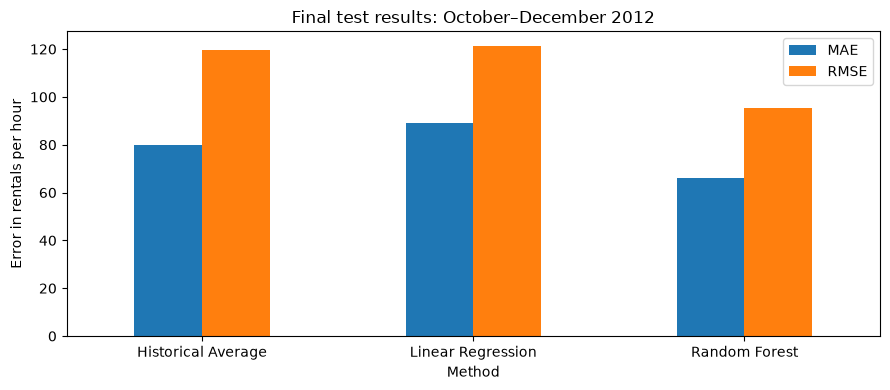

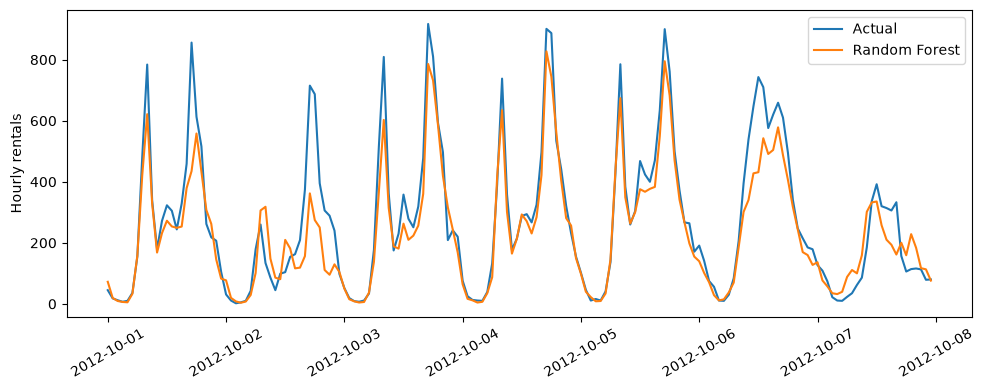

In [12]:
results.set_index("Method")[["MAE", "RMSE"]].plot.bar(figsize=(9, 4), rot=0)
plt.ylabel("Error in rentals per hour")
plt.title("Final test results: October–December 2012")
plt.tight_layout()
plt.show()
week = test["timestamp"] < test["timestamp"].min() + pd.Timedelta(days=7)
plt.figure(figsize=(10, 4))
plt.plot(test.loc[week, "timestamp"], y_test[week], label="Actual")
plt.plot(test.loc[week, "timestamp"], p_rf[week], label="Random Forest")
plt.ylabel("Hourly rentals")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


## 7. Check high-demand errors
Define high demand using the pre-test 90th percentile, then assess test records above and below that threshold. Bias = prediction − actual; negative bias means underprediction. Actual test demand identifies the groups retrospectively; this is error analysis, not advance detection of peak hours.


In [13]:
errors = test[["cnt"]].copy()
errors["prediction"] = p_rf
errors["absolute_error"] = abs(errors["prediction"] - errors["cnt"])
errors["bias"] = errors["prediction"] - errors["cnt"]
peak_threshold = y_past.quantile(0.9)
errors["high_demand"] = errors["cnt"] >= peak_threshold
print("High-demand threshold:", peak_threshold)
peak_results = errors.groupby("high_demand").agg(hours=("cnt", "size"), MAE=("absolute_error", "mean"), bias=("bias", "mean"))
peak_results.round(2)


High-demand threshold: 441.0


,hours,MAE,bias
high_demand,,,
False,1850,49.30,-22.48
True,318,164.44,-162.32


## 8. Live demo
Before presenting, run all cells in order and keep the Colab session connected. During the demo, run only the next two cells; do not retrain.

**Recorded case:** Use the first working-day 08:00 record in the test set. Show inputs, prediction, and actual rentals. This uses historical conditions and observed weather; it is not a present-day forecast.


In [14]:
example = test[(test["workingday"] == 1) & (test["hr"] == 8)].iloc[[0]]
example_cat = encoder.transform(example[cat_cols])
example_X = np.hstack([example_cat, example[num_cols]])
print("Historical time:", example["timestamp"].iloc[0])
print(example[features].to_string(index=False))
print("Predicted rentals:", round(rf.predict(example_X)[0], 1))
print("Actual rentals:", example["cnt"].iloc[0])


Historical time: 2012-10-01 08:00:00
 season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp  atemp  hum  windspeed
      4   1    10   8        0        1           1           2  0.46 0.4545 0.77     0.1045
Predicted rentals: 621.5
Actual rentals: 784


**Hypothetical scenario:** Set `demo_hour = 14` and hold other inputs fixed. There is no actual outcome attached to this modified scenario. The prediction change is not a causal effect of changing the hour.


In [15]:
demo_hour = 14
scenario = example.copy()
scenario["hr"] = demo_hour
scenario_cat = encoder.transform(scenario[cat_cols])
scenario_X = np.hstack([scenario_cat, scenario[num_cols]])
print("Hypothetical hour:", demo_hour)
print("Predicted rentals:", round(rf.predict(scenario_X)[0], 1))


Hypothetical hour: 14
Predicted rentals: 114.1


## 9. Conclusions and limitations
Calculate the reduction in test RMSE relative to the historical-average baseline and report high-demand bias. Error reduction is not percentage accuracy or measured cost savings.


In [16]:
rf_rmse = results.loc[results["Method"] == "Random Forest", "RMSE"].iloc[0]
base_rmse = results.loc[results["Method"] == "Historical Average", "RMSE"].iloc[0]
improvement = (base_rmse - rf_rmse) / base_rmse * 100
print(f"Random Forest test RMSE: {rf_rmse:.2f} rentals/hour")
print(f"RMSE reduction relative to the historical baseline: {improvement:.1f}%")
print(f"High-demand bias: {peak_results.loc[True, 'bias']:.1f} rentals/hour")


Random Forest test RMSE: 95.22 rentals/hour
RMSE reduction relative to the historical baseline: 20.4%
High-demand bias: -162.3 rentals/hour


### Business interpretation
Working and non-working days need different hourly planning profiles. Random Forest reduces test RMSE by about 20.4% relative to the historical baseline, but still underpredicts high-demand hours. Use estimates to inform planning alongside operational judgment.

### Limitations
- One city, 2011–2012: results do not establish current or other-city demand.
- Inputs use observed weather; advance prediction would require weather forecasts and new evaluation.
- There are 165 unrecorded hours and only three severe-weather records.
- System-wide rental counts do not identify station-level inventory or repositioning needs.
- The test period was inspected in an earlier version; this is not a fresh independent test.
- Only a small set of model settings was compared; rolling time validation is a possible extension.
